# Phase 3 - A DQN Market Maker, From Scratch

We now let a neural network *learn* a quoting policy from experience, with no knowledge of the Avellaneda-Stoikov formula, and ask whether it can match or beat that analytic baseline.

**DQN in one paragraph.** The agent learns an action-value function $Q(s,a)$ - the expected discounted future reward of quoting with offsets $a$ in state $s$. Acting greedily on $Q$ gives the policy. Three tricks make it stable:
- **experience replay** - store transitions and train on random minibatches, breaking the correlation between consecutive market steps;
- **a target network** - compute the bootstrap target with a frozen copy of the net so we are not chasing a moving target;
- **epsilon-greedy exploration** - act randomly early, greedily late, so the agent discovers the fill/inventory tradeoff.

We use **Double DQN** (online net selects the next action, target net evaluates it) to curb Q-value overestimation, and a **Huber** loss on the temporal-difference error.

> Training is done by `scripts/train_dqn.py`, which writes `runs/dqn/{dqn.pt, history.json}`. This notebook loads those artifacts so it stays fast and reproducible. Re-run the script to retrain.

In [1]:
import json, pathlib
import numpy as np
import matplotlib.pyplot as plt

from quant_mm.sim import MarketMakingEnv, MMEnvConfig
from quant_mm.agents import DQN, AvellanedaStoikovAgent, ASConfig, FixedSymmetricAgent, RandomAgent
from quant_mm.eval import run_episode, evaluate, summary_table

cfg = MMEnvConfig()
env = MarketMakingEnv(cfg)

# Resolve runs/dqn whether the kernel runs from the project root or notebooks/.
run_dir = next(p for p in [pathlib.Path('runs/dqn'), pathlib.Path('../runs/dqn')] if p.exists())
dqn = DQN.load(str(run_dir / 'dqn.pt'))
history = json.loads((run_dir / 'history.json').read_text())
print('loaded best DQN with', sum(p.numel() for p in dqn.online.parameters()), 'parameters')

loaded best DQN with 19472 parameters


## 1. The learning curve
Out-of-sample (evaluation-seed) PnL and Sharpe as training progresses, alongside the exploration rate. We overlay the Avellaneda-Stoikov baseline as the bar to clear.

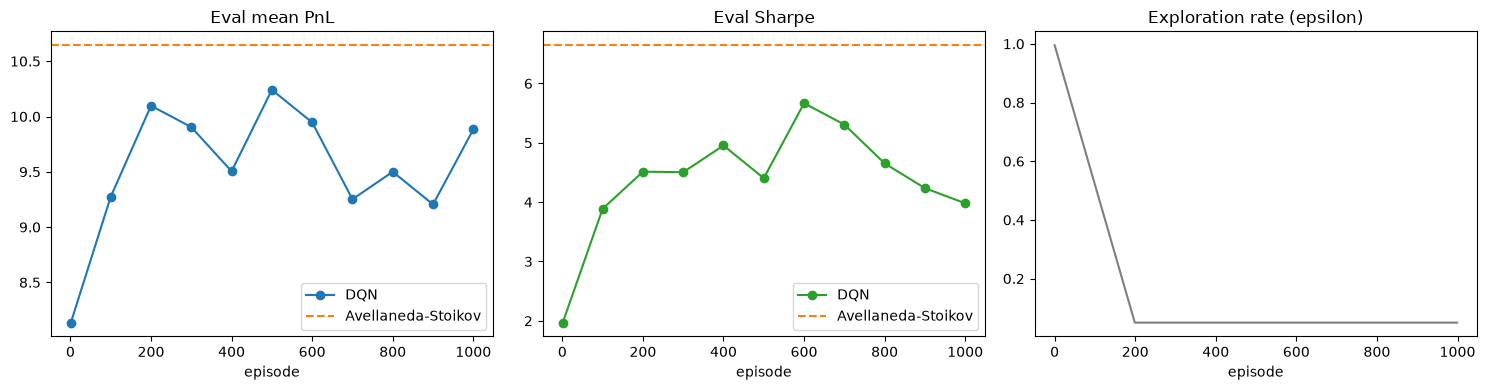

In [2]:
as_agent = AvellanedaStoikovAgent(cfg, ASConfig(gamma=0.1, kappa=40.0))
as_res = evaluate(env, as_agent, n_episodes=200, seed0=1_000_000)

ev = history['eval_episode']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ev, history['eval_pnl'], 'o-', color='tab:blue', label='DQN')
axes[0].axhline(as_res['pnl_mean'], ls='--', color='tab:orange', label='Avellaneda-Stoikov')
axes[0].set_title('Eval mean PnL'); axes[0].set_xlabel('episode'); axes[0].legend()
axes[1].plot(ev, history['eval_sharpe'], 'o-', color='tab:green', label='DQN')
axes[1].axhline(as_res['sharpe'], ls='--', color='tab:orange', label='Avellaneda-Stoikov')
axes[1].set_title('Eval Sharpe'); axes[1].set_xlabel('episode'); axes[1].legend()
axes[2].plot(history['episode'], history['epsilon'], color='tab:gray')
axes[2].set_title('Exploration rate (epsilon)'); axes[2].set_xlabel('episode')
plt.tight_layout(); plt.show()

## 2. Head-to-head on identical market seeds
The fair comparison: every agent is evaluated on the *same* set of evaluation seeds, so they face identical price paths and order flow.

In [3]:
agents = {
    'Random': RandomAgent(cfg, seed=0),
    'Fixed(3 ticks)': FixedSymmetricAgent(cfg, 3),
    'Avellaneda-Stoikov': as_agent,
    'DQN (learned)': dqn,
}
results = {name: evaluate(env, ag, n_episodes=300, seed0=2_000_000) for name, ag in agents.items()}
print(summary_table(results))

agent                             pnl_mean             pnl_std              sharpe            win_rate  mean_abs_inventory           avg_fills
----------------------------------------------------------------------------------------------------------------------------------------------
Random                              8.6164              4.1402              2.0811              0.9667             20.2413            581.1633
Fixed(3 ticks)                     11.5754              4.2136              2.7472              0.9867             19.7425            500.1433
Avellaneda-Stoikov                 10.3872              1.6009              6.4885              1.0000              6.6330            588.4300
DQN (learned)                       9.8096              1.6176              6.0643              1.0000              5.8990            427.5533


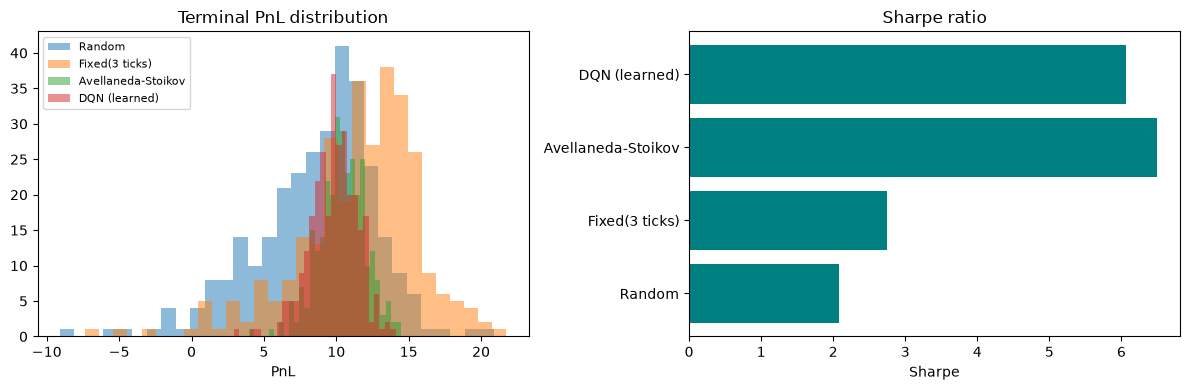

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    axes[0].hist(r['pnls'], bins=30, alpha=0.5, label=name)
axes[0].set_title('Terminal PnL distribution'); axes[0].set_xlabel('PnL'); axes[0].legend(fontsize=8)
names = list(results); sharpes = [results[n]['sharpe'] for n in names]
axes[1].barh(names, sharpes, color='teal'); axes[1].set_title('Sharpe ratio'); axes[1].set_xlabel('Sharpe')
plt.tight_layout(); plt.show()

## 3. Did the DQN *learn* to manage inventory?
We never told it about reservation prices. If it discovered inventory management on its own, its greedy action should **skew** with inventory just like Avellaneda-Stoikov: quote the bid wider and the ask tighter when long (to sell down), and vice-versa when short.

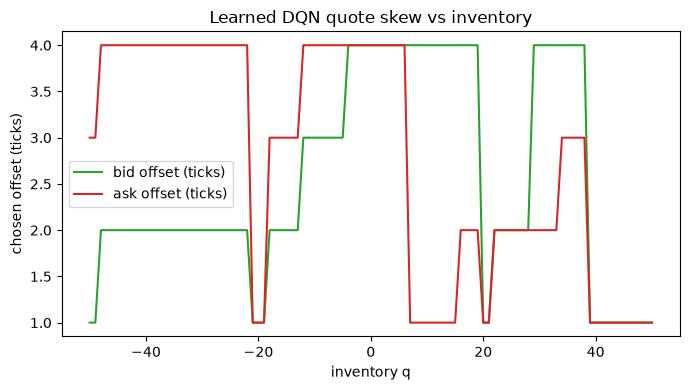

If the green line rises and the red line falls with inventory, the DQN rediscovered the AS skew.


In [5]:
qs = np.arange(-cfg.max_inventory, cfg.max_inventory + 1)
bid_off, ask_off = [], []
for q in qs:
    obs = np.array([q / cfg.max_inventory, 0, 0.3, 0.5, 0, 1], dtype=np.float32)
    a = dqn.act(obs)
    b, k = divmod(a, cfg.n_offsets)
    bid_off.append(b + 1); ask_off.append(k + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(qs, bid_off, label='bid offset (ticks)', color='tab:green')
ax.plot(qs, ask_off, label='ask offset (ticks)', color='tab:red')
ax.set_xlabel('inventory q'); ax.set_ylabel('chosen offset (ticks)')
ax.set_title('Learned DQN quote skew vs inventory'); ax.legend()
plt.tight_layout(); plt.show()
print('If the green line rises and the red line falls with inventory, the DQN rediscovered the AS skew.')

## 4. One episode: DQN vs Avellaneda-Stoikov on the same path

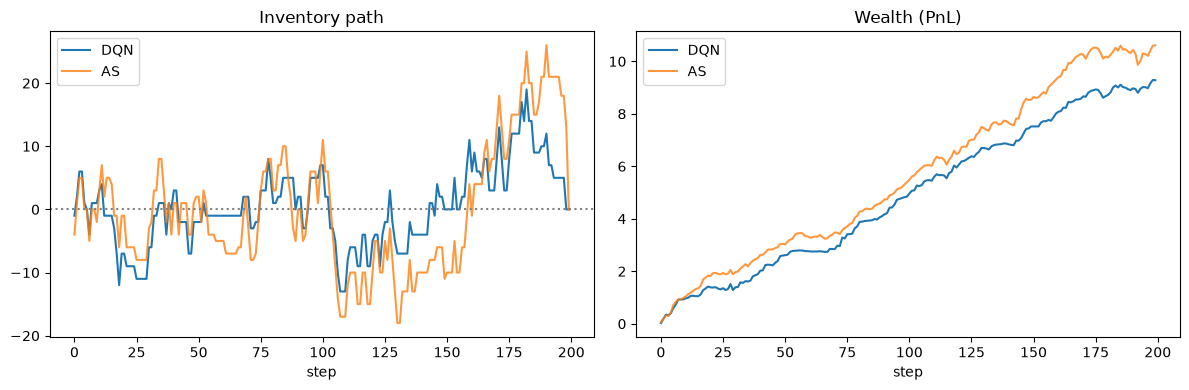

DQN terminal PnL 9.281 | AS terminal PnL 10.615


In [6]:
seed = 2_222
ep_dqn = run_episode(env, dqn, seed=seed)
ep_as = run_episode(env, as_agent, seed=seed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep_dqn.inventory, label='DQN', color='tab:blue')
axes[0].plot(ep_as.inventory, label='AS', color='tab:orange', alpha=0.8)
axes[0].axhline(0, ls=':', color='gray'); axes[0].set_title('Inventory path'); axes[0].set_xlabel('step'); axes[0].legend()
axes[1].plot(ep_dqn.wealth, label='DQN', color='tab:blue')
axes[1].plot(ep_as.wealth, label='AS', color='tab:orange', alpha=0.8)
axes[1].set_title('Wealth (PnL)'); axes[1].set_xlabel('step'); axes[1].legend()
plt.tight_layout(); plt.show()
print(f'DQN terminal PnL {ep_dqn.terminal_pnl:.3f} | AS terminal PnL {ep_as.terminal_pnl:.3f}')

---
**Takeaway.** A DQN trained purely on reward - never shown the Avellaneda-Stoikov formula - learns to quote a two-sided market and skew against its inventory. The head-to-head on identical seeds shows where it stands versus the analytic optimum. Whether it *beats* AS or merely matches it, the interesting result is the same: the structure of optimal market making is recoverable from experience alone.

Next: **Phase 4** - PPO (continuous quote offsets) and a three-way comparison.